# Chapter 3: Variations, errors and transport

Six experiments from the chapter:

1. Two gyros on bodies that move as one, and why their readings differ.
2. Variation formulas on $SO(3)$ and $S^2$, checked by finite differences along real families of curves.
3. Three attitude error functions, and how long each lingers near half a turn.
4. Transport maps: the compatibility test, and an arrow carried around an octant of the sphere.
5. Dead reckoning with a wrong start: invariant errors against Euler-angle differences.
6. Errors equal variations to first order.

Runs on NumPy, SciPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(3)
I3 = np.eye(3)
e1, e2, e3 = I3


def hat(x):
    return np.array([[0, -x[2], x[1]], [x[2], 0, -x[0]], [-x[1], x[0], 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def exp_so3(w):
    th = np.linalg.norm(w)
    if th < 1e-12:
        return I3 + hat(w)
    K = hat(w / th)
    return I3 + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def log_so3(R):
    th = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    return vee(R - R.T) / 2 if th < 1e-10 else th / (2 * np.sin(th)) * vee(R - R.T)


def unit(v):
    return np.asarray(v, float) / np.linalg.norm(v)


def fd(f, x, h=1e-5):
    """Central finite difference."""
    return (f(x + h) - f(x - h)) / (2 * h)


def curve_on_SO3(Omega, R0, T=2.0):
    """Integrate R' = R hat(Omega(t)) and return R(t) as a function."""
    sol = solve_ivp(lambda t, y: (y.reshape(3, 3) @ hat(Omega(t))).ravel(), [0, T], R0.ravel(),
                    rtol=1e-12, atol=1e-13, dense_output=True)
    return lambda t: sol.sol(t).reshape(3, 3)

## 1. Two gyros, one motion

The reference spins about the world vertical at 1 rad/s. The body does the same,
but its frame is mounted a quarter turn away about its first axis.

In [2]:
def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1.0]])


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1.0, 0, 0], [0, c, -s], [0, s, c]])


Rd = lambda t: Rz(t)
R = lambda t: Rz(t) @ Rx(np.pi / 2)
t = 0.7
Omega_d = vee(Rd(t).T @ fd(Rd, t))
Omega = vee(R(t).T @ fd(R, t))
print("reference gyro Omega_d =", Omega_d.round(6))
print("body gyro      Omega   =", Omega.round(6))
print("naive error  |Omega - Omega_d|          =", np.linalg.norm(Omega - Omega_d).round(4))
print("transported  |Omega - R^T Rd Omega_d|   =", np.linalg.norm(Omega - R(t).T @ Rd(t) @ Omega_d).round(10))

reference gyro Omega_d = [0. 0. 1.]
body gyro      Omega   = [-0.  1.  0.]
naive error  |Omega - Omega_d|          = 1.4142
transported  |Omega - R^T Rd Omega_d|   = 0.0


## 2. Variations, by finite differences

Build a curve $R(t)$, a variation field $\eta(t)$ and the family $R_\epsilon(t) = R(t)\exp(\epsilon\,\eta(t)^\wedge)$.
Then difference the body rate across the family and compare with $\delta\Omega = \dot\eta + \Omega\times\eta$.

In [3]:
Omega_fun = lambda t: np.array([np.sin(t), 0.6 * np.cos(2 * t), 0.4 + 0.3 * t])
eta_fun = lambda t: np.array([0.5 * np.cos(t), 0.3 * t, np.sin(1.3 * t) - 0.2])
R_ref = curve_on_SO3(Omega_fun, exp_so3([0.3, -0.5, 0.2]))

R_eps = lambda t, eps: R_ref(t) @ exp_so3(eps * eta_fun(t))
Omega_eps = lambda t, eps: vee(R_eps(t, eps).T @ fd(lambda s: R_eps(s, eps), t))

t = 0.9
dOmega_fd = fd(lambda e: Omega_eps(t, e), 0.0, h=1e-4)
dOmega = fd(eta_fun, t) + np.cross(Omega_fun(t), eta_fun(t))
print("finite difference :", dOmega_fd.round(6))
print("eta_dot + Om x eta:", dOmega.round(6))
print("eta_dot alone     :", fd(eta_fun, t).round(6), "  <- misses the cross term")

finite difference : [-0.670817 -0.056344  0.761065]
eta_dot + Om x eta: [-0.670817 -0.056344  0.761065]
eta_dot alone     : [-0.391663  0.3       0.507197]   <- misses the cross term


The same on the sphere. The field $\xi(t)$ is kept perpendicular to $q(t)$ at every instant.
Compare three candidate formulas for $\delta\omega$.

In [4]:
q_ref = lambda t: unit([np.cos(t) * np.cos(0.4 * t), np.sin(t) * np.cos(0.4 * t) + 0.3, 0.5 + np.sin(0.4 * t)])
a_fun = lambda t: np.array([np.sin(0.7 * t) + 0.2, np.cos(1.1 * t), 0.5 * t])


def xi_fun(t):
    q = q_ref(t)
    return a_fun(t) - (a_fun(t) @ q) * q


q_eps = lambda t, eps: exp_so3(eps * xi_fun(t)) @ q_ref(t)
omega_eps = lambda t, eps: np.cross(q_eps(t, eps), fd(lambda s: q_eps(s, eps), t))

t = 0.8
q, xi, xidot = q_ref(t), xi_fun(t), fd(xi_fun, t)
omega = np.cross(q, fd(q_ref, t))
domega_fd = fd(lambda e: omega_eps(t, e), 0.0, h=1e-4)
print("finite difference        :", domega_fd.round(6))
print("xi_dot - 2 omega x xi    :", (xidot - 2 * np.cross(omega, xi)).round(6), "  <- correct")
print("xi_dot -   omega x xi    :", (xidot - np.cross(omega, xi)).round(6), "  <- tangential part only")
print("xi_dot +   omega x xi    :", (xidot + np.cross(omega, xi)).round(6), "  <- sign borrowed from SO(3)")
print("q . delta omega =", (q @ domega_fd).round(6), "  (not zero: delta omega is not tangent)")

finite difference        : [ 1.122929 -1.251563  0.230446]
xi_dot - 2 omega x xi    : [ 1.122929 -1.251563  0.230446]   <- correct
xi_dot -   omega x xi    : [ 1.218248 -1.110181  0.347849]   <- tangential part only
xi_dot +   omega x xi    : [ 1.408884 -0.827417  0.582655]   <- sign borrowed from SO(3)
q . delta omega = -0.207021   (not zero: delta omega is not tangent)


## 3. Heights, slopes and lingering

For a relative rotation by $\theta$ about a fixed axis, three error functions and their slopes.

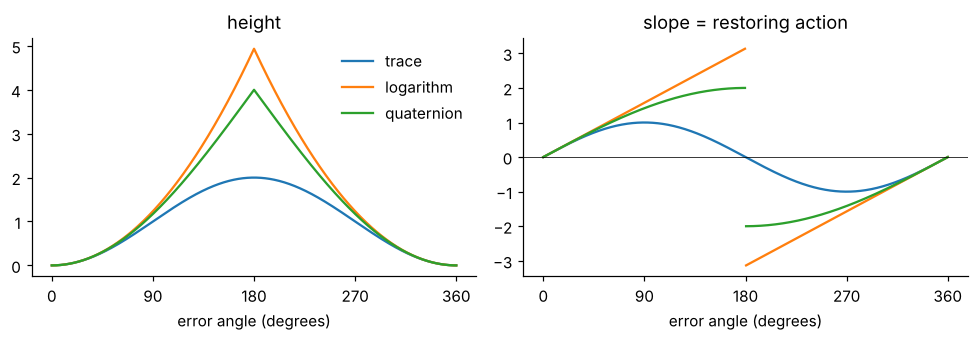

In [5]:
deg = np.linspace(0, 360, 721)
th = np.radians(deg)
fold = np.minimum(th, 2 * np.pi - th)
side = np.where(th <= np.pi, 1.0, -1.0)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(deg, 1 - np.cos(th), label="trace")
ax[0].plot(deg, 0.5 * fold**2, label="logarithm")
ax[0].plot(deg, 4 * (1 - np.cos(fold / 2)), label="quaternion")
ax[0].set_title("height")
ax[0].legend(frameon=False)
ax[1].plot(deg, np.sin(th))
for y in (side * fold, side * 2 * np.sin(fold / 2)):
    y = y.copy()
    y[deg == 180] = np.nan
    ax[1].plot(deg, y)
ax[1].axhline(0, color="k", lw=0.5)
ax[1].set_title("slope = restoring action")
for a in ax:
    a.set_xlabel("error angle (degrees)")
    a.set_xticks([0, 90, 180, 270, 360])
plt.tight_layout()
plt.show()

One axis, unit inertia, $\ddot\theta = -k_p\,e(\theta) - k_d\,\dot\theta$, started at rest near half a turn.

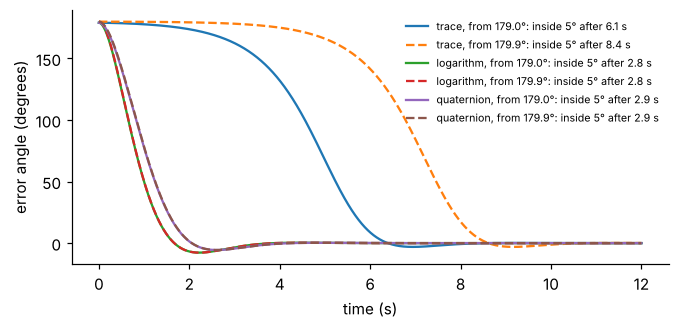

unstable rate at 180 deg: 1.035 1/s, so 2.22 s per factor of ten


In [6]:
kp, kd = 4.0, 2 * np.sqrt(2)
laws = {"trace": np.sin, "logarithm": lambda a: a, "quaternion": lambda a: 2 * np.sin(a / 2)}


def respond(law, th0_deg, T=12.0):
    sol = solve_ivp(lambda t, y: [y[1], -kp * laws[law](y[0]) - kd * y[1]], [0, T], [np.radians(th0_deg), 0.0],
                    rtol=1e-10, atol=1e-12, dense_output=True)
    tt = np.linspace(0, T, 6001)
    return tt, np.degrees(sol.sol(tt)[0])


def settle(tt, a, band=5.0):
    return tt[np.nonzero(np.abs(a) > band)[0][-1] + 1]


plt.figure(figsize=(7, 3))
for law in laws:
    for th0, ls in [(179.0, "-"), (179.9, "--")]:
        tt, a = respond(law, th0)
        plt.plot(tt, a, ls, label=f"{law}, from {th0}°: inside 5° after {settle(tt, a):.1f} s")
plt.xlabel("time (s)")
plt.ylabel("error angle (degrees)")
plt.legend(frameon=False, fontsize=7)
plt.show()
lam = (-kd + np.sqrt(kd**2 + 4 * kp)) / 2
print(f"unstable rate at 180 deg: {lam:.3f} 1/s, so {np.log(10) / lam:.2f} s per factor of ten")

## 4. Transport

**The compatibility test.** Move $R$ and $R_d$ along arbitrary curves and compare $\dot\Psi$ by finite differences
with $e\cdot e_{\text{vel}}$. Run it for the transported velocity error and for the naive difference, with equal
and unequal weights.

In [7]:
def Psi(R, Rd, G):
    return np.trace(G @ (I3 - Rd.T @ R))


def e_R(R, Rd, G):
    return vee(G @ Rd.T @ R - R.T @ Rd @ G)


Omd_fun = lambda t: np.array([0.3 * np.cos(t), -0.5, 0.4 * np.sin(2 * t)])
Rd_ref = curve_on_SO3(Omd_fun, exp_so3([-0.4, 0.1, 0.6]))
t = 1.1
R, Rd, Om, Omd = R_ref(t), Rd_ref(t), Omega_fun(t), Omd_fun(t)
for name, G in [("equal weights  ", I3 / 2), ("unequal weights", np.diag([0.9, 0.6, 0.3]))]:
    dPsi = fd(lambda s: Psi(R_ref(s), Rd_ref(s), G), t)
    print(name, "| dPsi/dt =", f"{dPsi:+.6f}",
          "| e_R . (Om - R^T Rd Omd) =", f"{e_R(R, Rd, G) @ (Om - R.T @ Rd @ Omd):+.6f}",
          "| e_R . (Om - Omd) =", f"{e_R(R, Rd, G) @ (Om - Omd):+.6f}")

C = 0.5 * (np.trace(R.T @ Rd) * I3 - R.T @ Rd)
print("d/dt e_R, finite difference:", fd(lambda s: e_R(R_ref(s), Rd_ref(s), I3 / 2), t).round(6))
print("C e_Omega                  :", (C @ (Om - R.T @ Rd @ Omd)).round(6))

equal weights   | dPsi/dt = +0.340792 | e_R . (Om - R^T Rd Omd) = +0.340792 | e_R . (Om - Omd) = +0.340792
unequal weights | dPsi/dt = +0.305332 | e_R . (Om - R^T Rd Omd) = +0.305332 | e_R . (Om - Omd) = +0.272034
d/dt e_R, finite difference: [ 0.454934 -0.19605   0.255923]
C e_Omega                  : [ 0.454934 -0.19605   0.255923]


On the sphere: $e_q = q_d\times q$, $e_\omega = \omega - (I - qq^\top)\omega_d$.

In [8]:
qd_ref = lambda t: unit([0.4 + np.sin(0.9 * t), np.cos(0.6 * t), 0.8 + 0.2 * t])
t = 0.6
q, qd = q_ref(t), qd_ref(t)
om, omd = np.cross(q, fd(q_ref, t)), np.cross(qd, fd(qd_ref, t))
e_q = np.cross(qd, q)
e_om = om - (I3 - np.outer(q, q)) @ omd
print("dPsi_q/dt      =", fd(lambda s: 1 - q_ref(s) @ qd_ref(s), t).round(8))
print("e_q . e_omega  =", (e_q @ e_om).round(8))

dPsi_q/dt      = 0.00424318
e_q . e_omega  = 0.00424318


**An arrow around an octant.** Parallel transport along a great circle from $a$ to $b$ is the rotation
about $a\times b$ through the angle between them.

In [9]:
def carry(v, a, b):
    return exp_so3(np.arccos(np.clip(a @ b, -1, 1)) * unit(np.cross(a, b))) @ v


v0 = e1                       # at the pole e3, pointing down the meridian towards e1
v1 = carry(v0, e3, e1)
v2 = carry(v1, e1, e2)
v3 = carry(v2, e2, e3)
print("start :", v0, "\nfinish:", v3.round(12))
print("turned by", np.degrees(np.arccos(v0 @ v3)).round(6), "degrees; enclosed area =", np.degrees(4 * np.pi / 8), "degrees")

start : [1. 0. 0.] 
finish: [0. 1. 0.]
turned by 90.0 degrees; enclosed area = 90.0 degrees


## 5. Dead reckoning with a wrong start

Truth and estimate integrate the same gyro signal. The estimate starts 5° wrong.

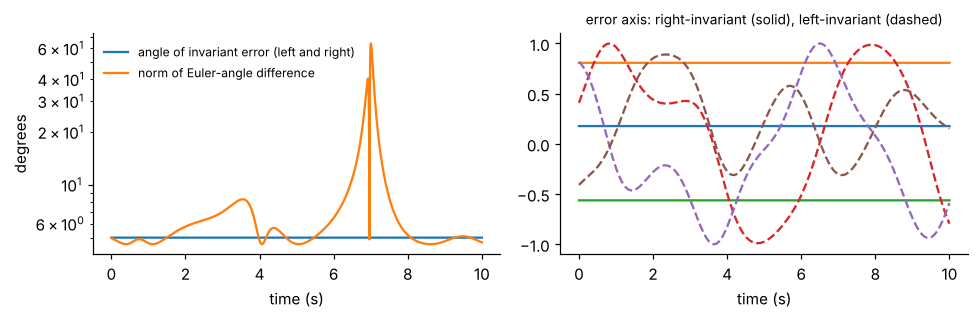

Euler-angle difference wanders between 4.6 and 64.0 degrees


In [10]:
gyro = lambda t: np.array([1.2 * np.sin(1.3 * t), 0.9 * np.cos(0.7 * t), 0.8 + 0.5 * np.sin(2.1 * t)])
R0 = Rz(0.3) @ Rx(-0.2)
R_true = curve_on_SO3(gyro, R0, T=10)
R_hat = curve_on_SO3(gyro, R0 @ exp_so3(np.radians(5) * unit([1, 2, -1])), T=10)


def euler_zyx(R):
    return np.array([np.arctan2(R[1, 0], R[0, 0]), -np.arcsin(np.clip(R[2, 0], -1, 1)), np.arctan2(R[2, 1], R[2, 2])])


tt = np.linspace(0, 10, 2001)
right = np.degrees([np.linalg.norm(log_so3(R_hat(t) @ R_true(t).T)) for t in tt])
left_axis = np.array([unit(log_so3(R_true(t).T @ R_hat(t))) for t in tt])
right_axis = np.array([unit(log_so3(R_hat(t) @ R_true(t).T)) for t in tt])
eul = []
for t in tt:
    d = euler_zyx(R_hat(t)) - euler_zyx(R_true(t))
    eul.append(np.degrees(np.linalg.norm((d + np.pi) % (2 * np.pi) - np.pi)))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(tt, right, label="angle of invariant error (left and right)")
ax[0].plot(tt, eul, label="norm of Euler-angle difference")
ax[0].set_yscale("log")
ax[0].set_xlabel("time (s)")
ax[0].set_ylabel("degrees")
ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(tt, right_axis, "-")
ax[1].plot(tt, left_axis, "--")
ax[1].set_xlabel("time (s)")
ax[1].set_title("error axis: right-invariant (solid), left-invariant (dashed)", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Euler-angle difference wanders between {min(eul):.1f} and {max(eul):.1f} degrees")

## 6. Errors are variations, to first order

Place the body at $R = R_d\exp(\epsilon\,\eta^\wedge)$ along a tumbling reference and shrink $\epsilon$.

In [11]:
t = 1.0
Rd, Omd = Rd_ref(t), Omd_fun(t)
eta, etadot = eta_fun(t), fd(eta_fun, t)
dOmega = etadot + np.cross(Omd, eta)
print("  eps   |e_R - eps eta|  |e_Om - eps eta_dot|  |e_Om - eps dOmega|")
for eps in (0.4, 0.2, 0.1, 0.05):
    Rp = lambda s: Rd_ref(s) @ exp_so3(eps * eta_fun(s))
    Rn = Rp(t)
    Omn = vee(Rn.T @ fd(Rp, t))
    eR = e_R(Rn, Rd, I3 / 2)
    eOm = Omn - Rn.T @ Rd @ Omd
    print(f"  {eps:<5} {np.linalg.norm(eR - eps * eta):.2e}         {np.linalg.norm(eOm - eps * etadot):.2e}"
          f"              {np.linalg.norm(eOm - eps * dOmega):.2e}")

  eps   |e_R - eps eta|  |e_Om - eps eta_dot|  |e_Om - eps dOmega|
  0.4   6.83e-03         3.83e-02              2.33e-01
  0.2   8.58e-04         9.60e-03              1.10e-01
  0.1   1.07e-04         2.40e-03              5.36e-02
  0.05  1.34e-05         6.01e-04              2.65e-02


## Starting points for the exercises

- **Exercise 3.3.** Replace `xi_fun` above by `a_fun` (not perpendicular to $q$) and rerun the $S^2$ cell.
- **Exercise 3.5.** In `respond`, set a nonzero initial rate and add noise to the angle before it enters `laws[law]`.
  For the logarithm and quaternion laws, wrap the angle into $(-\pi, \pi]$ first.
- **Exercise 3.6.** Replace the transport in `e_om` by the parallel transport `carry(omd, qd, q)` and rerun the test.
- **Exercise 3.7.** Difference `R(t) @ Rd(t).T` in the first experiment and compare with $w - w_d$ in the world frame.